Matplotlib is building the font cache; this may take a moment.


Web Data Extracted: 20
                                 Product  Price Category  Rating Source
0                   A Light in the Attic  51.77    Books       3    Web
1                     Tipping the Velvet  53.74    Books       1    Web
2                             Soumission  50.10    Books       1    Web
3                          Sharp Objects  47.82    Books       4    Web
4  Sapiens: A Brief History of Humankind  54.23    Books       5    Web

API Data Extracted: 20
                         Product  Price Category  Rating Source
0  Essence Mascara Lash Princess   9.99   beauty    2.56    API
1  Eyeshadow Palette with Mirror  19.99   beauty    2.86    API
2                Powder Canister  14.99   beauty    4.64    API
3                   Red Lipstick  12.99   beauty    4.36    API
4                Red Nail Polish   8.99   beauty    4.32    API

Integrated Dataset:
                                             Product  Price Category  Rating  \
0                               A Li

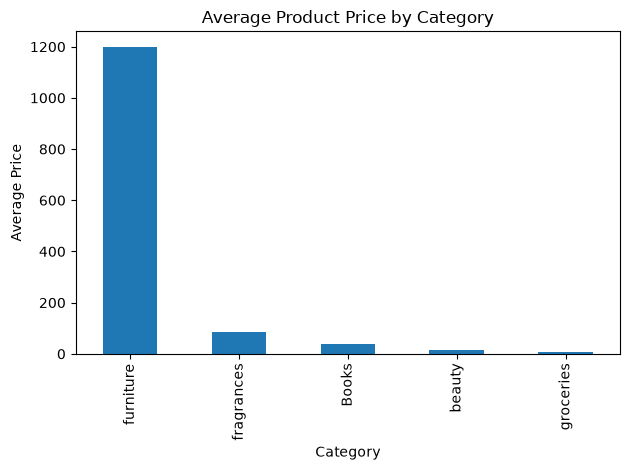


Integrated dataset saved successfully.


In [ ]:

# DSP LAB - UNIT II
# Extracting and Integrating Web and API Data
# for E-Commerce Business Intelligence

import requests
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Step 1: Extract data from an e-commerce webpage
web_url = "https://books.toscrape.com/"

response = requests.get(
    web_url,
    timeout=20
)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

web_products = []

for item in soup.select("article.product_pod"):
    title = item.h3.a["title"]
    price_text = item.select_one(".price_color").get_text(
        strip=True
    )
    rating_class = item.select_one(
        ".star-rating"
    )["class"]

    rating_words = [
        "One", "Two", "Three", "Four", "Five"
    ]

    rating = next(
        (rating_words.index(word) + 1
         for word in rating_class
         if word in rating_words),
        None
    )

    web_products.append({
        "Product": title,
        "Price": float(
            price_text.replace("£", "").replace("Â", "")
        ),
        "Category": "Books",
        "Rating": rating,
        "Source": "Web"
    })

web_df = pd.DataFrame(web_products)

print("Web Data Extracted:", len(web_df))
print(web_df.head())

# Step 2: Extract data from a REST API
api_url = "https://dummyjson.com/products?limit=20"

api_response = requests.get(
    api_url,
    timeout=20
)
api_response.raise_for_status()

api_data = api_response.json()["products"]

api_products = []

for product in api_data:
    api_products.append({
        "Product": product["title"],
        "Price": product["price"],
        "Category": product["category"],
        "Rating": product["rating"],
        "Source": "API"
    })

api_df = pd.DataFrame(api_products)

print("\nAPI Data Extracted:", len(api_df))
print(api_df.head())

# Step 3: Integrate both datasets
integrated_df = pd.concat(
    [web_df, api_df],
    ignore_index=True
)

# Step 4: Check and clean the integrated data
integrated_df = integrated_df.drop_duplicates()

integrated_df["Price"] = pd.to_numeric(
    integrated_df["Price"], errors="coerce"
)

integrated_df["Rating"] = pd.to_numeric(
    integrated_df["Rating"], errors="coerce"
)

integrated_df = integrated_df.dropna(
    subset=["Product", "Price", "Rating"]
)

print("\nIntegrated Dataset:")
print(integrated_df.head(10))

# Step 5: Business intelligence analysis
print("\nTotal Products:", len(integrated_df))

print("Average Price:",
      round(integrated_df["Price"].mean(), 2))

print("Average Rating:",
      round(integrated_df["Rating"].mean(), 2))

print("\nAverage Price by Source:")
print(integrated_df.groupby("Source")["Price"].mean())

print("\nAverage Rating by Category:")
print(integrated_df.groupby("Category")["Rating"].mean())

print("\nTop 5 Rated Products:")
print(
    integrated_df.sort_values(
        "Rating", ascending=False
    )[["Product", "Price", "Rating"]].head(5)
)

# Step 6: Visualize the data
category_price = integrated_df.groupby(
    "Category"
)["Price"].mean().sort_values(ascending=False)

category_price.plot(
    kind="bar",
    title="Average Product Price by Category",
    xlabel="Category",
    ylabel="Average Price"
)

plt.tight_layout()
plt.show()

# Step 7: Save the integrated dataset
integrated_df.to_csv(
    "integrated_ecommerce_data.csv",
    index=False
)

print("\nIntegrated dataset saved successfully.")